
--- SVM Results ---
Accuracy: 0.9824561403508771
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


--- Random Forest Results ---
Accuracy: 0.956140350877193
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



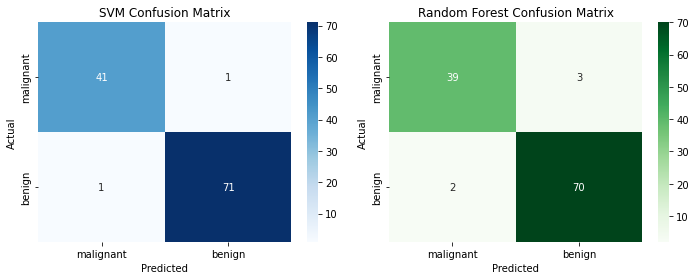


--- Model Comparison ---
           Model  Accuracy
0            SVM  0.982456
1  Random Forest  0.956140


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm = SVC(kernel="rbf", C=1.0)
svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

print("\n--- SVM Results ---")
print("Accuracy:", accuracy_score(y_test, svm_pred))
print(classification_report(
    y_test, svm_pred, target_names=data.target_names
))

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("\n--- Random Forest Results ---")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(
    y_test, rf_pred, target_names=data.target_names
))

svm_cm = confusion_matrix(y_test, svm_pred)
rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.heatmap(
    svm_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.subplot(1, 2, 2)
sns.heatmap(
    rf_cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

results = pd.DataFrame({
    "Model": ["SVM", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test, rf_pred)
    ]
})

print("\n--- Model Comparison ---")
print(results)